# Taller 4 – Segmentación de usuarios de Steam con Clustering

**Dataset:** Steam Video Games (Kaggle – tamber). Cada fila es un usuario, un juego y un comportamiento:
- `purchase`: el usuario compró el juego (`value` siempre es 1).
- `play`: el usuario jugó el juego (`value` = horas jugadas).

**Objetivo:** agrupar a los usuarios según cómo compran y juegan, describir cada grupo y proponer acciones de negocio.

## 1. Exploración de los datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

columnas = ["user_id", "game", "behavior", "value", "extra"]
df = pd.read_csv("steam-200k.csv", header=None, names=columnas)

df.head()

,user_id,game,behavior,value,extra
0,151603712,The Elder Scrolls V Skyrim,purchase,1.0,0
1,151603712,The Elder Scrolls V Skyrim,play,273.0,0
2,151603712,Fallout 4,purchase,1.0,0
3,151603712,Fallout 4,play,87.0,0
4,151603712,Spore,purchase,1.0,0


El archivo no trae encabezados, por eso se asignan los nombres de columna manualmente.

### 1.1 Dimensiones y tipos de variables

In [2]:
print("Dimensiones:", df.shape)
df.info()

Dimensiones: (200000, 5)
<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 5 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   user_id   200000 non-null  int64  
 1   game      200000 non-null  str    
 2   behavior  200000 non-null  str    
 3   value     200000 non-null  float64
 4   extra     200000 non-null  int64  
dtypes: float64(1), int64(2), str(2)
memory usage: 7.6 MB


Tenemos 200.000 registros y 5 columnas:
- `user_id` (numérica, pero es un identificador, no se usa como valor).
- `game` y `behavior` (categóricas).
- `value` (numérica continua: 1 en compras, horas en juego).
- `extra` (numérica, se revisa abajo).

### 1.2 Valores nulos

In [3]:
df.isnull().sum()

user_id     0
game        0
behavior    0
value       0
extra       0
dtype: int64

No hay valores nulos, no es necesario imputar nada.

### 1.3 Registros duplicados

In [4]:
print("Duplicados:", df.duplicated().sum())

Duplicados: 707


In [5]:
antes = df.shape[0]
df = df.drop_duplicates()
despues = df.shape[0]
print(f"Antes: {antes} | Despues: {despues} | Eliminadas: {antes - despues}")

Antes: 200000 | Despues: 199293 | Eliminadas: 707


Se eliminan los 707 duplicados porque son registros repetidos exactos (mismo usuario, juego, comportamiento y valor) y contarían doble las compras u horas.

### 1.4 Revisión de variables categóricas y de la columna `extra`

In [6]:
print(df["behavior"].value_counts())
print()
print("Valores únicos de 'extra':", df["extra"].unique())
print("Usuarios únicos:", df["user_id"].nunique())
print("Juegos únicos:", df["game"].nunique())

behavior
purchase    128804
play         70489
Name: count, dtype: int64

Valores únicos de 'extra': [0]
Usuarios únicos: 12393


Juegos únicos: 5155


La columna `extra` solo tiene el valor 0, así que no aporta información y se descartará.

### 1.5 Estadísticos descriptivos

In [7]:
compras = df[df["behavior"] == "purchase"]
jugados = df[df["behavior"] == "play"]

print("Compras:", compras.shape)
print("Registros de juego:", jugados.shape)
print()
print("Estadísticos de horas jugadas:")
jugados["value"].describe()

Compras: (128804, 5)
Registros de juego: (70489, 5)

Estadísticos de horas jugadas:


count    70489.000000
mean        48.878063
std        229.335236
min          0.100000
25%          1.000000
50%          4.500000
75%         19.100000
max      11754.000000
Name: value, dtype: float64

Las horas jugadas tienen una mediana muy baja frente a la media y un máximo muy alto: la distribución está muy sesgada a la derecha (pocos usuarios juegan muchísimo).

In [8]:
juegos_comprados = compras.groupby("user_id")["game"].count()
juegos_comprados.describe()

count    12393.000000
mean        10.393287
std         35.635890
min          1.000000
25%          1.000000
50%          2.000000
75%          6.000000
max       1068.000000
Name: game, dtype: float64

La mitad de los usuarios ha comprado 2 juegos o menos, pero hay usuarios con más de 1.000. De nuevo, distribución muy sesgada.

### 1.6 Visualizaciones

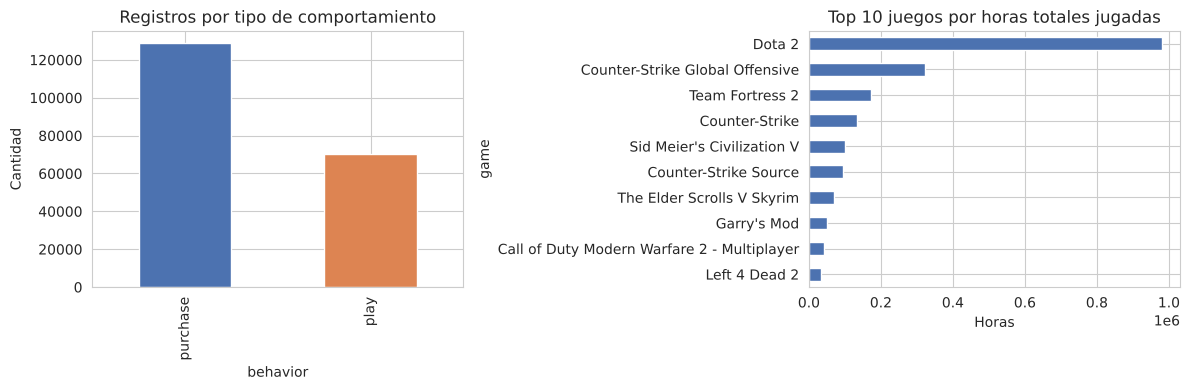

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

df["behavior"].value_counts().plot(kind="bar", ax=ax[0], color=["#4C72B0", "#DD8452"])
ax[0].set_title("Registros por tipo de comportamiento")
ax[0].set_ylabel("Cantidad")

top_juegos = jugados.groupby("game")["value"].sum().sort_values(ascending=False).head(10)
top_juegos.sort_values().plot(kind="barh", ax=ax[1], color="#4C72B0")
ax[1].set_title("Top 10 juegos por horas totales jugadas")
ax[1].set_xlabel("Horas")

plt.tight_layout()
plt.show()

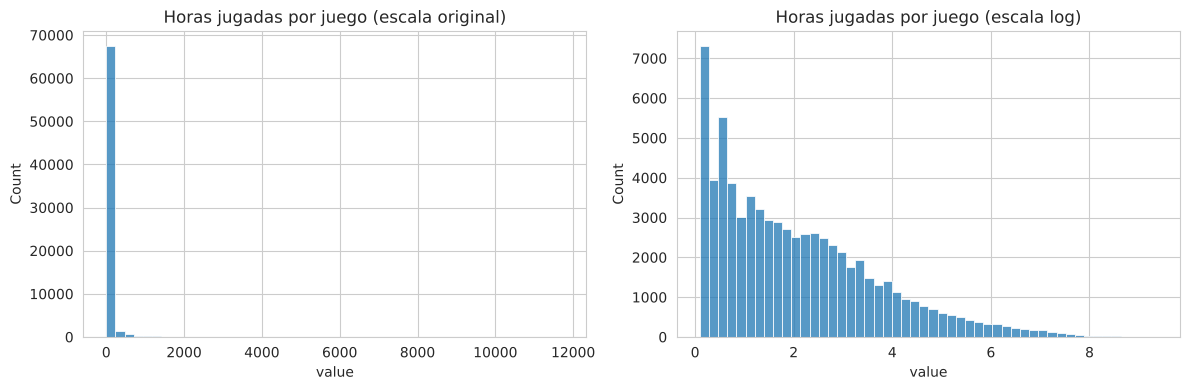

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(jugados["value"], bins=50, ax=ax[0])
ax[0].set_title("Horas jugadas por juego (escala original)")

sns.histplot(np.log1p(jugados["value"]), bins=50, ax=ax[1])
ax[1].set_title("Horas jugadas por juego (escala log)")

plt.tight_layout()
plt.show()

En escala original casi todo se concentra cerca de cero. Con logaritmo la distribución se ve mucho más interpretable; esto justifica usar una transformación logarítmica antes del clustering.

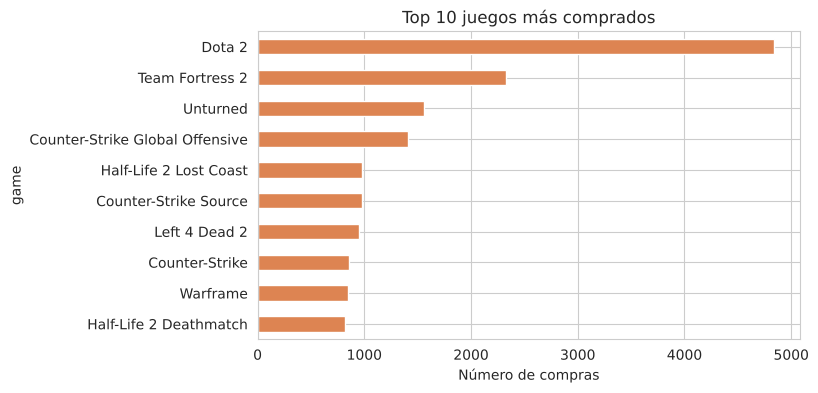

In [11]:
top_comprados = compras["game"].value_counts().head(10)
top_comprados.sort_values().plot(kind="barh", figsize=(7, 4), color="#DD8452")
plt.title("Top 10 juegos más comprados")
plt.xlabel("Número de compras")
plt.show()

## 2. Preparación de los datos

El dataset está a nivel **usuario–juego**, pero queremos segmentar **usuarios**. Por eso se construye una tabla con una fila por usuario y estas variables:

| Variable | Qué mide | Por qué se usa |
|---|---|---|
| `juegos_comprados` | Juegos distintos comprados | Comportamiento de compra |
| `juegos_jugados` | Juegos distintos con horas registradas | Variedad de juego |
| `horas_totales` | Suma de horas jugadas | Nivel de actividad |
| `horas_por_juego` | Horas totales / juegos jugados | Profundidad (juega mucho pocos juegos o poco muchos) |
| `tasa_juego` | Juegos jugados / juegos comprados | Si realmente usa lo que compra |

In [12]:
# Compras por usuario
compras_usuario = compras.groupby("user_id")["game"].nunique().rename("juegos_comprados")

# Juego por usuario
juego_usuario = jugados.groupby("user_id").agg(
    juegos_jugados=("game", "nunique"),
    horas_totales=("value", "sum")
)

usuarios = pd.concat([compras_usuario, juego_usuario], axis=1)

# Usuarios que compraron pero nunca jugaron quedan con NaN -> 0 horas y 0 juegos jugados
usuarios = usuarios.fillna(0)

usuarios["horas_por_juego"] = np.where(
    usuarios["juegos_jugados"] > 0,
    usuarios["horas_totales"] / usuarios["juegos_jugados"].replace(0, 1),
    0
)

# Algunos juegos aparecen jugados sin registro de compra (gratuitos), por eso se limita a 1
usuarios["tasa_juego"] = (usuarios["juegos_jugados"] / usuarios["juegos_comprados"]).clip(upper=1)

print(usuarios.shape)
usuarios.describe().round(2)

(12393, 5)


,juegos_comprados,juegos_jugados,horas_totales,horas_por_juego,tasa_juego
count,12393.00,12393.00,12393.00,12393.00,12393.00
mean,10.39,5.69,278.01,74.32,0.73
std,35.64,17.08,760.27,283.75,0.34
min,1.00,0.00,0.00,0.00,0.00
25%,1.00,1.00,1.30,1.10,0.50
50%,2.00,1.00,13.50,7.90,1.00
75%,6.00,3.00,155.60,39.00,1.00
max,1068.00,498.00,11754.00,11754.00,1.00


**Decisiones tomadas:**
- **Rellenar con 0:** un usuario sin registros `play` simplemente no ha jugado, no es un dato faltante.
- **Descartar `extra` y `game`:** `extra` es constante; el nombre del juego tiene más de 5.000 valores y codificarlo generaría miles de columnas sin aportar a esta segmentación de comportamiento.
- **Limitar `tasa_juego` a 1:** evita valores mayores a 1 por juegos gratuitos.

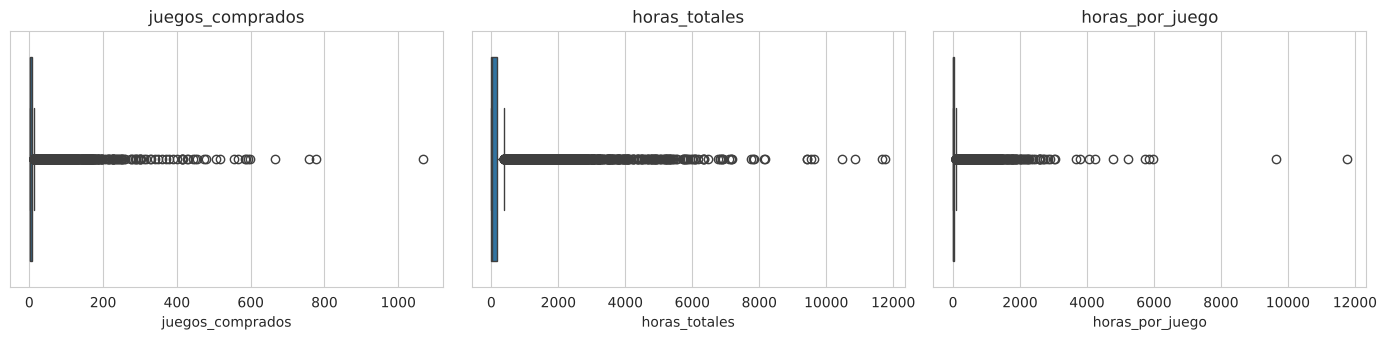

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for i, col in enumerate(["juegos_comprados", "horas_totales", "horas_por_juego"]):
    sns.boxplot(x=usuarios[col], ax=ax[i])
    ax[i].set_title(col)
plt.tight_layout()
plt.show()

Hay muchos valores atípicos. **No se eliminan**, porque esos usuarios extremos (los que más juegan o más compran) son justamente un segmento valioso para el negocio. En su lugar se aplica:

1. **Transformación logarítmica (`log1p`)** a las variables de conteo y horas, para reducir el sesgo y que los extremos no dominen el modelo.
2. **Estandarización (`StandardScaler`)**, porque K-Means usa distancias y las variables tienen escalas muy distintas (horas en miles vs. tasa entre 0 y 1).

Se deja fuera `juegos_jugados` del modelo porque está muy correlacionada con `juegos_comprados` (se comprueba abajo) y duplicaría el peso de esa información.

In [14]:
usuarios.corr().round(2)

,juegos_comprados,juegos_jugados,horas_totales,horas_por_juego,tasa_juego
juegos_comprados,1.00,0.91,0.47,-0.02,-0.15
juegos_jugados,0.91,1.00,0.54,-0.03,-0.06
horas_totales,0.47,0.54,1.00,0.49,-0.05
horas_por_juego,-0.02,-0.03,0.49,1.00,0.01
tasa_juego,-0.15,-0.06,-0.05,0.01,1.00


In [15]:
from sklearn.preprocessing import StandardScaler

variables_modelo = ["juegos_comprados", "horas_totales", "horas_por_juego", "tasa_juego"]

X = usuarios[variables_modelo].copy()
X["juegos_comprados"] = np.log1p(X["juegos_comprados"])
X["horas_totales"] = np.log1p(X["horas_totales"])
X["horas_por_juego"] = np.log1p(X["horas_por_juego"])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pd.DataFrame(X_scaled, columns=variables_modelo).describe().round(2)

,juegos_comprados,horas_totales,horas_por_juego,tasa_juego
count,12393.00,12393.00,12393.00,12393.00
mean,-0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00
min,-0.74,-1.26,-1.29,-2.11
25%,-0.74,-0.92,-0.89,-0.66
50%,-0.36,-0.16,-0.11,0.79
75%,0.44,0.82,0.69,0.79
max,5.17,2.59,3.75,0.79


Después de escalar, todas las variables tienen media 0 y desviación 1.

## 3. Modelado

**Algoritmo elegido: K-Means**

- Tenemos más de 12.000 usuarios; K-Means es rápido y escala bien.
- Las variables son numéricas y quedaron escaladas, que es lo que necesita K-Means.
- Produce grupos fáciles de interpretar a partir de sus centroides, útil para negocio.
- **DBSCAN** se descartó porque con datos tan concentrados cerca de cero tiende a dejar casi todo en un solo grupo y marcar muchos usuarios como ruido.
- **Jerárquico** se descartó porque con 12.000 registros es lento y consume mucha memoria.

### 3.1 Elección del número de clusters (k)

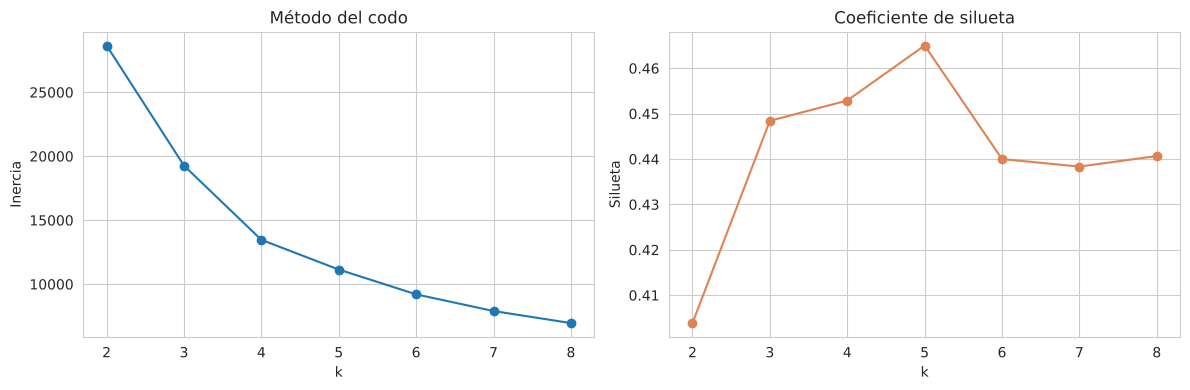

k=2: silueta=0.404
k=3: silueta=0.448
k=4: silueta=0.453
k=5: silueta=0.465
k=6: silueta=0.440
k=7: silueta=0.438
k=8: silueta=0.441


In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inercias = []
siluetas = []
rango_k = range(2, 9)

for k in rango_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    etiquetas = km.fit_predict(X_scaled)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_scaled, etiquetas, sample_size=5000, random_state=42))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(rango_k, inercias, marker="o")
ax[0].set_title("Método del codo")
ax[0].set_xlabel("k")
ax[0].set_ylabel("Inercia")

ax[1].plot(rango_k, siluetas, marker="o", color="#DD8452")
ax[1].set_title("Coeficiente de silueta")
ax[1].set_xlabel("k")
ax[1].set_ylabel("Silueta")

plt.tight_layout()
plt.show()

for k, s in zip(rango_k, siluetas):
    print(f"k={k}: silueta={s:.3f}")

El codo se marca alrededor de **k = 4** y la silueta en k=4 es de las más altas. k=5 tiene una silueta un poco mayor, pero al revisarlo divide en dos un grupo que se interpreta igual. Se elige **k = 4** porque da grupos claros y explicables para negocio.

In [17]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
usuarios["cluster"] = kmeans.fit_predict(X_scaled)

usuarios["cluster"].value_counts().sort_index()

cluster
0    2336
1    2930
2    2343
3    4784
Name: count, dtype: int64

### 3.2 Visualización de los clusters (PCA a 2 dimensiones)

Varianza explicada: [0.56 0.32] Total: 0.88


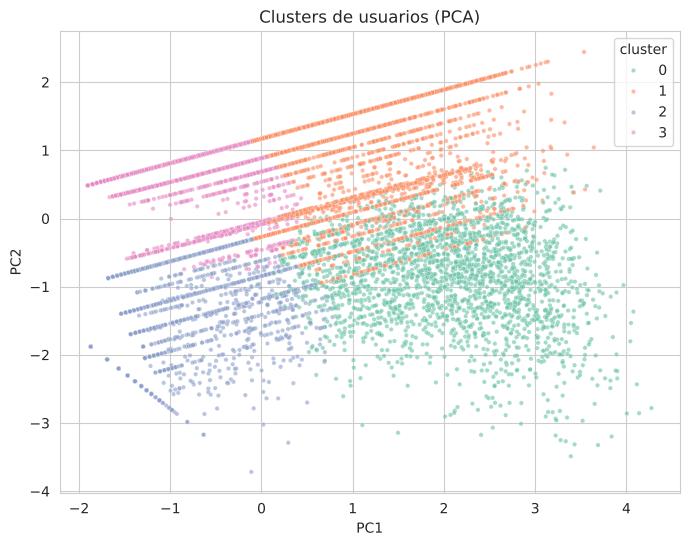

In [18]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
componentes = pca.fit_transform(X_scaled)
print("Varianza explicada:", pca.explained_variance_ratio_.round(2), "Total:", pca.explained_variance_ratio_.sum().round(2))

plt.figure(figsize=(8, 6))
sns.scatterplot(x=componentes[:, 0], y=componentes[:, 1], hue=usuarios["cluster"],
                palette="Set2", s=10, alpha=0.6)
plt.title("Clusters de usuarios (PCA)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

## 4. Interpretación de los clusters

In [19]:
resumen = usuarios.groupby("cluster")[["juegos_comprados", "juegos_jugados", "horas_totales",
                                        "horas_por_juego", "tasa_juego"]].median().round(1)
resumen["n_usuarios"] = usuarios["cluster"].value_counts().sort_index()
resumen["%_usuarios"] = (resumen["n_usuarios"] / len(usuarios) * 100).round(1)
resumen

,juegos_comprados,juegos_jugados,horas_totales,horas_por_juego,tasa_juego,n_usuarios,%_usuarios
cluster,,,,,,,
0,21.0,13.0,506.0,32.8,0.6,2336,18.8
1,2.0,1.0,128.0,75.0,1.0,2930,23.6
2,3.0,1.0,0.3,0.3,0.2,2343,18.9
3,1.0,1.0,2.6,2.2,1.0,4784,38.6


Se usa la **mediana** para describir cada grupo porque la media se ve muy afectada por los usuarios extremos.

/tmp/ipykernel_391/2225932037.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=usuarios, x="cluster", y=col, ax=ax[i], palette="Set2", showfliers=False)
/tmp/ipykernel_391/2225932037.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=usuarios, x="cluster", y=col, ax=ax[i], palette="Set2", showfliers=False)
/tmp/ipykernel_391/2225932037.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=usuarios, x="cluster", y=col, ax=ax[i], palette="Set2", showfliers=False)


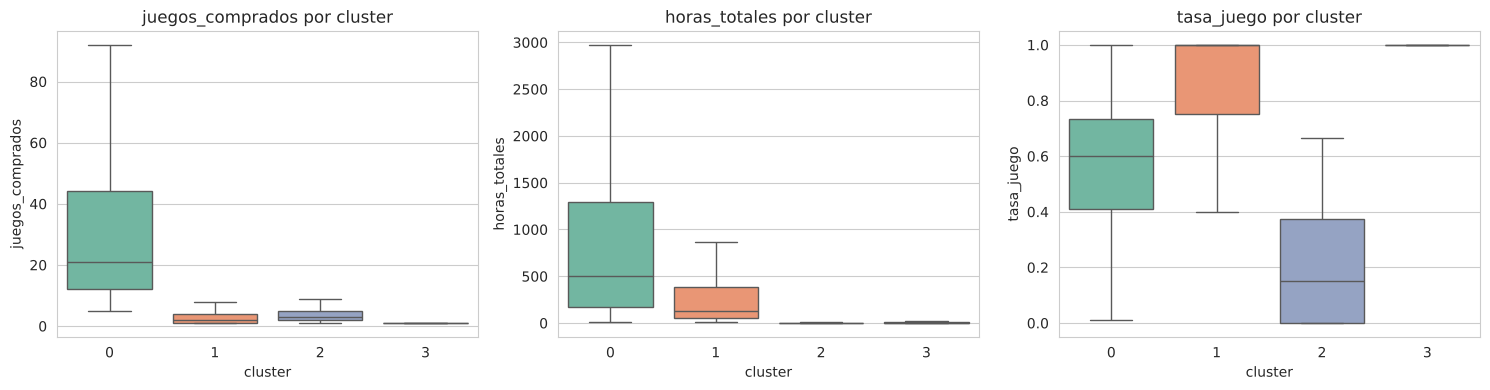

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(["juegos_comprados", "horas_totales", "tasa_juego"]):
    sns.boxplot(data=usuarios, x="cluster", y=col, ax=ax[i], palette="Set2", showfliers=False)
    ax[i].set_title(col + " por cluster")
plt.tight_layout()
plt.show()

In [21]:
# Se asigna el nombre según el perfil de cada centroide (para que no dependa del número del cluster)
med = usuarios.groupby("cluster")[["juegos_comprados", "horas_totales", "tasa_juego"]].median()

nombres = {}
nombres[med["juegos_comprados"].idxmax()] = "Coleccionistas Muy Activos"
nombres[med["tasa_juego"].idxmin()] = "Compradores Inactivos"
restantes = [c for c in med.index if c not in nombres]
nombres[med.loc[restantes, "horas_totales"].idxmax()] = "Jugadores Dedicados"
nombres[[c for c in med.index if c not in nombres][0]] = "Jugadores Casuales"

usuarios["segmento"] = usuarios["cluster"].map(nombres)
print({int(k): v for k, v in nombres.items()})
usuarios.groupby("segmento")[["juegos_comprados", "horas_totales", "horas_por_juego", "tasa_juego"]].median().round(1)

{0: 'Coleccionistas Muy Activos', 2: 'Compradores Inactivos', 1: 'Jugadores Dedicados', 3: 'Jugadores Casuales'}


,juegos_comprados,horas_totales,horas_por_juego,tasa_juego
segmento,,,,
Coleccionistas Muy Activos,21.0,506.0,32.8,0.6
Compradores Inactivos,3.0,0.3,0.3,0.2
Jugadores Casuales,1.0,2.6,2.2,1.0
Jugadores Dedicados,2.0,128.0,75.0,1.0


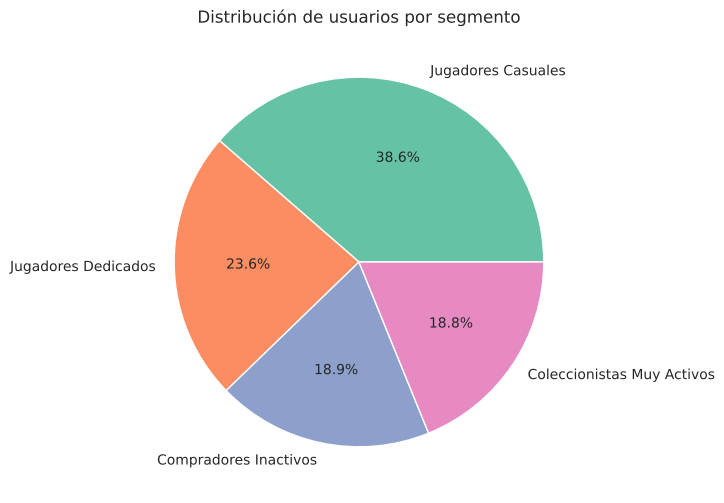

In [22]:
usuarios["segmento"].value_counts().plot(kind="pie", autopct="%1.1f%%", figsize=(6, 6),
                                         colors=sns.color_palette("Set2"))
plt.title("Distribución de usuarios por segmento")
plt.ylabel("")
plt.show()

In [23]:
# Juegos más jugados (por horas) en cada segmento
jugados_seg = jugados.merge(usuarios[["segmento"]], left_on="user_id", right_index=True)
for seg in usuarios["segmento"].unique():
    top = jugados_seg[jugados_seg["segmento"] == seg].groupby("game")["value"].sum().sort_values(ascending=False).head(5)
    print(f"\n{seg}:")
    print(top.round(0).to_string())


Coleccionistas Muy Activos:
game
Dota 2                             435425.0
Counter-Strike Global Offensive    264472.0
Team Fortress 2                    108379.0
Counter-Strike                     101481.0
Counter-Strike Source               71069.0

Compradores Inactivos:
game
Dota 2                             1507.0
Counter-Strike Source               827.0
Counter-Strike                      628.0
Team Fortress 2                     438.0
Counter-Strike Global Offensive     422.0

Jugadores Dedicados:
game
Dota 2                             535317.0
Team Fortress 2                     62050.0
Sid Meier's Civilization V          58473.0
Counter-Strike Global Offensive     57098.0
Counter-Strike                      32072.0

Jugadores Casuales:
game
Dota 2                             9435.0
Team Fortress 2                    2806.0
Unturned                           1253.0
Counter-Strike Global Offensive     780.0
Left 4 Dead 2                       485.0


### Descripción de los segmentos

**🟢 Coleccionistas Muy Activos (~19%)**
- Compran muchos juegos (mediana ~21) y acumulan cientos de horas (mediana ~500 h).
- Juegan muchos títulos distintos, aunque dejan parte de su biblioteca sin abrir (tasa ~0.6).
- Son jugadores **frecuentes** y los que más compran. Es el segmento más valioso.

**🔵 Jugadores Dedicados (~24%)**
- Compran pocos juegos (mediana ~2) pero juegan muchísimo cada uno (mediana ~75 h por juego).
- Casi todo lo que compran lo juegan (tasa ~1).
- Son jugadores **frecuentes pero fieles a pocos títulos** (muchos juegos competitivos tipo Dota 2, CS, TF2).

**🟠 Compradores Inactivos (~19%)**
- Compran algunos juegos (mediana ~3) pero casi no juegan (mediana < 1 hora en total).
- Tasa de juego muy baja (~0.2): compran y no usan (probablemente por ofertas o bundles).
- Riesgo de abandono.

**🟣 Jugadores Casuales (~39%)**
- Tienen 1 juego y lo juegan poco (mediana ~2-3 horas).
- Es el grupo más grande. Son usuarios **ocasionales**, muchos probablemente nuevos o que solo probaron un juego.

**Diferencias principales:** el eje que más separa es la actividad (horas). Coleccionistas y Dedicados juegan mucho pero se diferencian en la cantidad de juegos que compran; Inactivos y Casuales juegan poco, pero los Inactivos sí compran varios juegos y los Casuales no.

## 5. Recomendaciones de negocio

| Segmento | Estrategia de marketing | Promociones | Prioridad fidelización |
|---|---|---|---|
| **Coleccionistas Muy Activos** | Programa VIP, acceso anticipado a lanzamientos, recomendaciones personalizadas según su biblioteca | Bundles, pases de temporada, descuentos por volumen, preventas | **Alta** – son los que más ingresos generan |
| **Jugadores Dedicados** | Contenido para su juego favorito y recomendación de juegos similares | DLCs, expansiones, ítems/cosméticos del juego que ya juegan, descuentos en títulos del mismo género | **Alta** – alto engagement, se pueden convertir en coleccionistas |
| **Compradores Inactivos** | Campañas de reactivación: recordar los juegos que ya tienen sin jugar | Eventos de fin de semana, logros/recompensas por jugar, guías de inicio. Evitar venderles más juegos por ahora | **Media** – primero reactivar, luego vender |
| **Jugadores Casuales** | Onboarding y descubrimiento: mostrar juegos populares y fáciles | Juegos free-to-play, demos, descuentos fuertes en el segundo juego, juegos baratos | **Baja-media** – volumen grande, buscar que den el paso a comprar más |

**¿A quién priorizar para fidelización?** A los **Coleccionistas Muy Activos** y a los **Jugadores Dedicados**, porque concentran la mayoría de las horas jugadas y de las compras. Perder un usuario de estos grupos cuesta mucho más que perder un casual.

**Información adicional que mejoraría la segmentación:**
- **Precio** pagado por cada juego y gasto total (hoy solo sabemos que compró, no cuánto).
- **Fechas** de compra y de juego, para medir recencia y frecuencia (modelo RFM) y detectar abandono.
- **Género** del juego, para segmentar por gustos (shooters, RPG, estrategia…).
- **Datos demográficos**: edad, país, plataforma.
- **Si el juego fue gratuito, regalo o comprado en oferta**, para separar a los compradores de ofertas.
- Interacción social: amigos, reseñas, logros.

## Conclusión

Con K-Means (k=4) sobre variables de comportamiento por usuario se identificaron cuatro segmentos bien diferenciados. El hallazgo principal es que una parte importante de los usuarios compra juegos que no usa, y otra parte juega mucho pero solo uno o dos títulos. Estas diferencias permiten diseñar campañas distintas para cada grupo en lugar de una estrategia única para todos.